# 02. 열 → 행 → 행 ICL 세 단계와 출력

[01 노트북](01_overview_and_cell_encoder.ipynb)은 TabPFN-3의 구조와 파라미터 수, 계산이 어디에 드는지, 그리고 과일 표의 셀이 셀 encoder에서 토큰이 되는 과정을 봤습니다. 이 노트북은 그 토큰을 세 단계에 차례로 통과시킵니다. 열마다 학습 행의 분포를 요약하고(열 단계), 행마다 토큰을 벡터 하나로 압축하고(행 단계), 그 행 벡터로 in-context learning을 한 뒤(행 ICL), 클래스 확률이나 bar 구간 logit을 냅니다(출력). 마지막으로 이 구조가 보장하는 성질을 확인합니다. v1부터 3.5까지의 차이는 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)에 있습니다.

다루는 흐름:

1. 열 단계 — inducing point로 열 요약하기
2. 행 단계 — CLS 토큰으로 행을 벡터 하나로
3. 행 ICL — 학습 행만 보는 24층과 QASSMax
4. 출력 — retrieval decoder
5. 구조가 보장하는 성질과 보장하지 않는 성질
6. 정리

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/05_tabpfn_v3/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn

from minipfn import set_seed
from minipfn.models import randomize_zero_weights
from minipfn.models.column_row_transformer import ColumnRowTransformer, ColumnRowTransformerConfig

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 앞 노트북에서 가져오는 것

01 노트북의 과일 표(feature 5개, 학습 행 4개, 테스트 행 2개)와 표준화한 값 `z`, 그리고 손 계산을 실제 모델과 맞춰 볼 작은 `ColumnRowTransformer`를 다시 만듭니다. 작은 모델은 01 노트북과 같은 설정(`ColumnRowTransformerConfig.tiny()`)과 같은 시드로 만들고, 0으로 시작한 가중치도 같은 함수(`minipfn.models.randomize_zero_weights`)로 채우므로 가중치가 같습니다.

In [3]:
fruit = pd.DataFrame(
    {
        "무게(g)": [210, 190, 320, 290, 200, 310],
        "당도(brix)": [13.5, 14.0, 11.0, 11.5, 13.0, 12.0],
        "지름(cm)": [7.5, 7.2, 9.0, 8.6, 7.4, 8.8],
        "산도(pH)": [3.4, 3.5, 3.9, 3.8, 3.4, 3.9],
        "껍질(mm)": [0.6, 0.5, 1.0, 0.9, 0.6, 1.0],
    }
)
y = np.array([0, 0, 1, 1])  # 학습 행의 정답: 0 = 사과, 1 = 배
n_train = 4
roles = ["학습 1", "학습 2", "학습 3", "학습 4", "테스트 5", "테스트 6"]

features = fruit.to_numpy(dtype=float)
mean = features[:n_train].mean(axis=0)
std = features[:n_train].std(axis=0)  # 모델과 같이 n으로 나눈 표준편차
z = (features - mean) / std
names = list(fruit.columns)
n_features = len(names)

torch.manual_seed(0)
tiny = randomize_zero_weights(ColumnRowTransformer(ColumnRowTransformerConfig.tiny())).eval()

x = torch.tensor(features, dtype=torch.float32)[None]  # (데이터셋 1, 행 6, feature 5)
y_train = torch.tensor(y, dtype=torch.float32)[None]  # (데이터셋 1, 학습 행 4)

## 1. 열 단계 — inducing point로 열 요약하기

열 단계는 열마다 따로 돕니다. 과일 표라면 '무게' 열의 토큰 6개(행 6개)는 '무게' 열끼리만, '당도' 열의 토큰은 '당도' 열끼리만 정보를 주고받습니다. 텐서 모양으로는 (데이터셋 × 열, 행, E)입니다.

한 열 안에서는 학습되는 벡터 몇 개를 중간에 두고 두 번에 나눠 봅니다. 이 벡터를 inducing point라고 부릅니다(Set Transformer의 ISAB).

1. **요약**: inducing point가 학습 행만 봅니다. 무게 열이라면 학습 행 4개(210g, 190g, 320g, 290g)를 보고 "이 열의 학습 행 값이 어떻게 분포하는가"를 inducing point마다 벡터 하나로 담습니다.
2. **펼치기**: 모든 행(학습 4개, 테스트 2개)이 그 요약을 봅니다.

**두 번에 나누는 이유는 계산량입니다.** 행 $R$개, 학습 행 $N$개, inducing point $M$개라고 합시다(3은 $M = 128$). v2·2.5의 sample attention처럼 모든 행이 학습 행을 직접 보면 열마다 $R \cdot N$을 계산합니다. 요약과 펼치기로 나누면 $M \cdot N + R \cdot M$이라, 행 수에 비례해서만 늘어납니다.

**손 계산 설정.** 무게 열 하나와 inducing point 2개(A, B)로 해 봅니다. 토큰 대신 표준화한 무게 값 하나만 씁니다. A는 무거운 행에, B는 가벼운 행에 높은 점수를 주도록 점수를 직접 정합니다. A의 점수는 $2 \times$ z값, B의 점수는 $-2 \times$ z값입니다. 실제 모델에서는 이 점수가 학습으로 정해집니다.

In [4]:
weight_z = z[:, 0]  # 무게 열의 표준화한 값 (행 6개)
grams = features[:, 0]
inducing_sign = {"inducing A (heavy)": 2.0, "inducing B (light)": -2.0}


def softmax(scores):
    e = np.exp(scores - scores.max())
    return e / e.sum()


summary_rows, summaries = {}, {}
for name, sign in inducing_sign.items():
    scores = sign * weight_z[:n_train]  # 학습 행 4개에만 점수를 준다 (테스트 행은 보지 않는다)
    weights = softmax(scores)
    summaries[name] = weights @ grams[:n_train]  # 요약 = 학습 행 무게의 가중 평균
    summary_rows[name] = dict(zip(roles[:n_train], weights, strict=True)) | {
        "요약 (가중 평균 g)": summaries[name]
    }
display(pd.DataFrame(summary_rows).T.round(2))

,학습 1,학습 2,학습 3,학습 4,요약 (가중 평균 g)
inducing A (heavy),0.01,0.01,0.74,0.24,310.54
inducing B (light),0.32,0.66,0.01,0.02,198.65


A는 배(320g, 290g)에 가중치를 몰아 요약이 310g쯤 되고, B는 사과(210g, 190g) 쪽으로 몰려 200g 가까이 됩니다. 학습 행 무게의 분포를 "무거운 무리"와 "가벼운 무리" 두 숫자로 요약한 셈입니다. 테스트 행은 요약에 들어가지 않습니다.

펼치기에서는 모든 행이 이 두 요약을 봅니다. 행의 점수를 요약과 가까울수록 크게( 점수 = $-|$무게 − 요약$| / 20$ ) 정해 보면 다음과 같습니다.

In [5]:
summary_values = np.array(list(summaries.values()))
broadcast_rows = {}
for i, role in enumerate(roles):
    scores = -np.abs(grams[i] - summary_values) / 20  # 요약과 가까울수록 큰 점수
    weights = softmax(scores)
    broadcast_rows[f"{role} ({grams[i]:.0f}g)"] = dict(zip(inducing_sign, weights, strict=True))
display(pd.DataFrame(broadcast_rows).T.round(2))

,inducing A (heavy),inducing B (light)
학습 1 (210g),0.01,0.99
학습 2 (190g),0.00,1.00
학습 3 (320g),1.00,0.00
학습 4 (290g),0.97,0.03
테스트 5 (200g),0.00,1.00
테스트 6 (310g),1.00,0.00


200g인 테스트 5는 B(가벼운 무리)를, 310g인 테스트 6은 A(무거운 무리)를 거의 다 가져옵니다. 테스트 행은 학습 행을 하나하나 보지 않고도 "내 무게는 이 열의 어느 쪽인가"를 알게 됩니다. 요약은 학습 행에서만 만들었으므로, 테스트 행끼리는 서로 영향을 주지 않습니다.

누가 누구를 보는지 표로 정리합니다. 행은 attend하는 쪽, 열은 attend받는 쪽이고 1이면 attend합니다.

In [6]:
m = 2
ind_names = [f"inducing {chr(65 + i)}" for i in range(m)]
summarize = pd.DataFrame(0, index=ind_names, columns=roles)
summarize.loc[:, roles[:n_train]] = 1  # inducing point → 학습 행
broadcast = pd.DataFrame(1, index=roles, columns=ind_names)  # 모든 행 → inducing point
print("① 요약: inducing point가 학습 행을 본다")
display(summarize)
print("② 펼치기: 모든 행이 inducing point를 본다")
display(broadcast)

① 요약: inducing point가 학습 행을 본다


,학습 1,학습 2,학습 3,학습 4,테스트 5,테스트 6
inducing A,1,1,1,1,0,0
inducing B,1,1,1,1,0,0


② 펼치기: 모든 행이 inducing point를 본다


,inducing A,inducing B
학습 1,1,1
학습 2,1,1
학습 3,1,1
학습 4,1,1
테스트 5,1,1
테스트 6,1,1


실제 모델에서는 이 두 attention 뒤에 각각 MLP가 붙고(`InducedBlock`), 이것을 3블록 반복합니다. 요약 쪽 attention에는 3절의 QASSMax를 써서 학습 행 수가 바뀌어도 요약이 흐려지지 않게 합니다. 토큰 모양은 열 단계에 들어가기 전과 같습니다.

In [7]:
captured = {}
hook = tiny.column_blocks[-1].register_forward_hook(
    lambda module, inputs, output: captured.update(column_out=output)
)
with torch.no_grad():
    tiny(x, y_train)
hook.remove()
print("열 단계 출력:", tuple(captured["column_out"].shape), " (데이터셋 × 열 5, 행 6, E)")
print(
    "inducing point:",
    tuple(tiny.column_blocks[0].inducing.shape),
    " (M, E) — 모든 열·데이터셋이 같이 쓰는 학습 파라미터",
)

열 단계 출력: (5, 6, 16)  (데이터셋 × 열 5, 행 6, E)
inducing point: (4, 16)  (M, E) — 모든 열·데이터셋이 같이 쓰는 학습 파라미터


## 2. 행 단계 — CLS 토큰으로 행을 벡터 하나로

열 단계를 지난 토큰은 이제 "이 행의 이 열 값이 열 전체에서 어디쯤인가"를 압니다. 행 단계는 행마다 따로 돌며, 그 행의 feature 토큰 $F$개 앞에 학습되는 CLS 토큰 $k$개(3은 4개)를 붙여 서로 attention합니다. 모양은 (데이터셋 × 행, $k + F$, E)입니다. 첫 학습 행의 토큰 줄은 이렇습니다.

In [8]:
k = 4  # TabPFN-3의 CLS 수
sequence = [f"CLS {i + 1}" for i in range(k)] + names
display(
    pd.DataFrame({"토큰": sequence, "RoPE 위치": range(len(sequence))}).set_index("RoPE 위치").T
)

RoPE 위치,0,1,2,3,4,5,6,7,8
토큰,CLS 1,CLS 2,CLS 3,CLS 4,무게(g),당도(brix),지름(cm),산도(pH),껍질(mm)


세 가지를 봅니다.

- **RoPE(base $10^5$)로 위치를 넣습니다.** CLS가 0~3번, feature가 4번부터 열 순서대로입니다. 그래서 이 단계는 feature 순서에 따라 결과가 달라집니다(5절에서 확인).
- **마지막 블록은 CLS만 query입니다.** 다음 단계에서 쓰는 것은 CLS 출력뿐이라, feature 토큰의 출력은 계산하지 않습니다.
- **CLS 출력 $k$개를 이어 붙여 행 벡터 하나로 만듭니다.** 3은 $4 \times 128 = 512$차원입니다.

이 단계가 끝나면 feature 수가 텐서 모양에서 사라집니다. feature가 5개든 2,000개든 행 하나는 512차원 벡터 하나이고, 01 노트북 2절에서 본 대로 24층짜리 행 ICL의 계산이 feature 수와 상관없어지는 지점이 여기입니다. 작은 모델(CLS 2개, E = 16)로 모양을 확인합니다.

In [9]:
captured = {}
hooks = [
    tiny.row_blocks[0].register_forward_pre_hook(
        lambda module, inputs: captured.update(row_in=inputs[0])
    ),
    tiny.row_blocks[-1].register_forward_hook(
        lambda module, inputs, output: captured.update(row_last=output)
    ),
    tiny.icl_layers[0].register_forward_pre_hook(
        lambda module, inputs: captured.update(icl_in=inputs[0])
    ),
]
with torch.no_grad():
    tiny(x, y_train)
for hook in hooks:
    hook.remove()
print(
    "행 단계 입력:      ",
    tuple(captured["row_in"].shape),
    " (데이터셋 × 행 6, CLS 2 + feature 5, E)",
)
print(
    "마지막 블록 출력:  ",
    tuple(captured["row_last"].shape),
    " (데이터셋 × 행 6, CLS 2, E) — CLS만 남는다",
)
print("행 ICL 입력:       ", tuple(captured["icl_in"].shape), " (데이터셋, 행 6, CLS 2 × E)")

행 단계 입력:       (6, 7, 16)  (데이터셋 × 행 6, CLS 2 + feature 5, E)
마지막 블록 출력:   (6, 2, 16)  (데이터셋 × 행 6, CLS 2, E) — CLS만 남는다
행 ICL 입력:        (1, 6, 32)  (데이터셋, 행 6, CLS 2 × E)


3의 실제 설정이면 마지막 줄이 (데이터셋, 행, 512)이고, 3.5는 CLS가 8개라 1,024입니다.

이 저장소가 정한 것이 하나 있습니다. 실제 모델은 대부분의 attention 출력층을 0으로 시작하는데(처음에는 잔차에 아무것도 더하지 않게), 행 단계만은 0으로 시작하지 않습니다. CLS 토큰은 attention으로만 그 행의 셀 정보를 받으므로, 0에서 시작하면 학습 초기에 모든 행 벡터가 같아지고 gradient가 거의 0(1e-8)이었습니다.

## 3. 행 ICL — 학습 행만 보는 24층과 QASSMax

행 벡터에 정답 embedding을 한 번 더 더합니다(01 노트북 3절 4단계와 다른 encoder이고 폭이 행 벡터 폭). 그 뒤 24층 Transformer가 행을 토큰으로 in-context learning을 합니다. attention 규칙은 v1의 행 Transformer와 같습니다. 학습 행은 학습 행끼리, 테스트 행은 학습 행만 봅니다.

In [10]:
allowed = np.zeros((len(roles), len(roles)), dtype=int)
allowed[:, :n_train] = 1  # 모든 행 → 학습 행
display(pd.DataFrame(allowed, index=roles, columns=roles))

,학습 1,학습 2,학습 3,학습 4,테스트 5,테스트 6
학습 1,1,1,1,1,0,0
학습 2,1,1,1,1,0,0
학습 3,1,1,1,1,0,0
학습 4,1,1,1,1,0,0
테스트 5,1,1,1,1,0,0
테스트 6,1,1,1,1,0,0


테스트 행에는 한 가지가 더 있습니다. 학습 행은 head 8개가 각자 key·value를 쓰지만, 테스트 행은 query head 8개가 모두 첫 head의 key·value 하나만 봅니다(multi-query attention). 테스트 행이 볼 key·value를 head마다 따로 들고 있지 않아도 되므로, 학습 행이 많을 때 추론 메모리가 줄어듭니다. 학습 행끼리의 attention은 그대로 head마다 따로입니다.

### 3.1 QASSMax — 행이 많아져도 attention이 흐려지지 않게

softmax에는 key가 많아질수록 가중치가 흐려지는 성질이 있습니다. 테스트 행 하나가 학습 행 $n$개를 보는데, 그중 딱 하나만 닮아서 점수가 4이고 나머지는 0이라고 합시다. 닮은 행이 받는 가중치는 $e^4 / (e^4 + n - 1)$입니다. 학습 행이 10개일 때는 대부분을 가져오지만, 1,000개만 되어도 0.05로 떨어집니다. 닮은 행이 하나뿐인데도 나머지 999개의 평균에 묻히는 것입니다.

scalable softmax는 query에 $s \cdot \log n$을 곱해 이것을 막습니다. 점수가 $4 \cdot s \log n$이 되니 가중치는 $n^{4s} / (n^{4s} + n - 1)$이고, $4s > 1$이면 $n$이 커질수록 오히려 1에 가까워집니다. $s = 0.5$로 두고 비교합니다.

,배율 s·log n,softmax,scalable softmax
학습 행 수 n,,,
10,1.151,0.858,0.917
100,2.303,0.355,0.990
1000,3.454,0.052,0.999
10000,4.605,0.005,1.000
100000,5.756,0.001,1.000
1000000,6.908,0.000,1.000


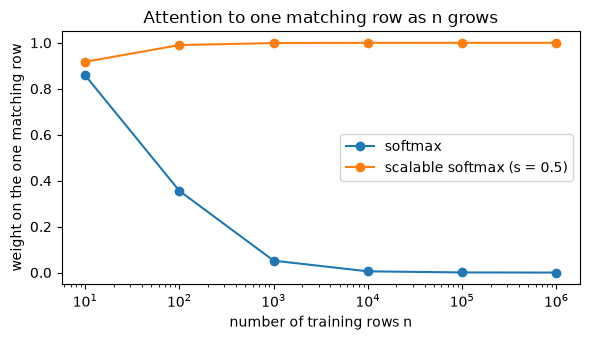

In [11]:
MATCH_SCORE, S = 4.0, 0.5
ssmax_rows = {}
for n in [10, 100, 1_000, 10_000, 100_000, 1_000_000]:
    plain = math.exp(MATCH_SCORE) / (math.exp(MATCH_SCORE) + n - 1)
    scaled_score = MATCH_SCORE * S * math.log(n)
    scaled = math.exp(scaled_score) / (math.exp(scaled_score) + n - 1)
    ssmax_rows[n] = {"배율 s·log n": S * math.log(n), "softmax": plain, "scalable softmax": scaled}
ssmax_table = pd.DataFrame(ssmax_rows).T.rename_axis("학습 행 수 n")
display(ssmax_table.round(3))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(ssmax_table.index, ssmax_table["softmax"], marker="o", label="softmax")
ax.plot(
    ssmax_table.index,
    ssmax_table["scalable softmax"],
    marker="o",
    label="scalable softmax (s = 0.5)",
)
ax.set_xscale("log")
ax.set_xlabel("number of training rows n")
ax.set_ylabel("weight on the one matching row")
ax.set_title("Attention to one matching row as n grows")
ax.legend()
plt.tight_layout()
plt.show()

TabPFN-3의 QASSMax(query-aware scalable softmax)는 이 배율을 학습합니다. 식은 $q \leftarrow q \cdot \text{base\_mlp}(\log n) \cdot (1 + \tanh(\text{query\_mlp}(q)))$입니다. $\text{base\_mlp}$는 $\log n$을 받아 head와 차원마다 배율을 내고(위의 $s \log n$을 학습하는 것), $\text{query\_mlp}$는 query마다 그 배율을 조금씩 조절합니다. $\text{query\_mlp}$의 마지막 층은 0으로 시작해서 처음에는 조절이 없습니다. 이 식은 보고서에는 없고 공개된 추론 코드(PriorLabs/TabPFN v9의 `architectures/tabpfn_v3*.py`, Apache 2.0)에서 확인했습니다. 이 저장소는 그 설계만 보고 코드와 가중치는 가져오지 않았습니다.

쓰는 곳은 key 수가 데이터셋마다 달라지는 attention입니다. 열 단계의 요약(inducing point → 학습 행), 행 ICL 24층, 4절의 retrieval decoder입니다. key가 늘 inducing point 128개인 열 단계의 펼치기, key가 행 하나의 토큰뿐인 행 단계에는 쓰지 않습니다. 이 저장소의 학습은 학습 행 2,048개까지의 표로 하는데(`recipes/tabpfn_v3.py`의 `paper`, `max_train_rows`) 추론은 그보다 훨씬 긴 표에도 하려면, key 수가 학습 때보다 훨씬 많아져도 attention이 버텨야 합니다. QASSMax가 그 역할을 합니다.

## 4. 출력 — retrieval decoder

회귀는 v2와 같은 bar distribution입니다. 테스트 행 벡터를 구간 5,000개의 logit으로 바꿉니다(3은 2층 MLP, 3.5는 잔차 MLP 뒤 Linear 하나).

분류는 방식이 바뀌었습니다. v2·2.5는 테스트 행 벡터를 Linear에 넣어 클래스 10개의 logit을 냈습니다. 3의 retrieval decoder는 이렇게 합니다.

1. 테스트 행이 query, 학습 행이 key가 되어 attention 가중치를 냅니다.
2. 그 가중치로 학습 행의 one-hot 정답을 평균해 클래스 확률 $p$를 만듭니다.
3. logit은 $\log(\max(p, 10^{-5}) + 3 \times 10^{-5})$입니다.
4. 이것을 head 6개로 따로 하고 확률을 평균합니다.

"닮은 학습 행의 정답을 투표로 모은다"는 것이라, 클래스 수에 매인 파라미터가 없습니다. 테스트 5 하나와 head 하나로 손 계산을 해 봅니다. 테스트 5(200g, 사과처럼 생긴 행)의 점수를 학습 행마다 정해 둡니다.

In [12]:
scores = np.array([2.0, 1.5, -1.0, -0.5])  # 테스트 5 → 학습 1~4 (사과 둘과 더 닮았다)
weights = softmax(scores)
onehot = np.eye(3)[y]  # 학습 행 정답의 one-hot (클래스 3개 자리)
p = weights @ onehot
logit = np.log(np.maximum(p, 1e-5) + 3e-5)

display(pd.DataFrame({"attention 가중치": weights, "정답": y}, index=roles[:n_train]).round(3))
display(
    pd.DataFrame(
        {"확률 p": p, "logit": logit},
        index=["클래스 0 (사과)", "클래스 1 (배)", "클래스 2 (학습 행에 없음)"],
    ).round(3)
)

,attention 가중치,정답
학습 1,0.575,0
학습 2,0.349,0
학습 3,0.029,1
학습 4,0.047,1


,확률 p,logit
클래스 0 (사과),0.924,-0.079
클래스 1 (배),0.076,-2.578
클래스 2 (학습 행에 없음),0.000,-10.127


사과인 학습 1·2에 가중치 0.92가 몰려 클래스 0의 확률이 0.92가 됩니다. 학습 행에 없는 클래스 2는 확률이 정확히 0이고, logit은 $\log(10^{-5} + 3 \times 10^{-5}) \approx -10.1$로 바닥에 깔립니다. $10^{-5}$로 자르는 것은 확률이 0인 클래스의 log가 $-\infty$가 되지 않게 하는 것입니다.

실제 모델로 확인합니다. 정답 embedding 수(`n_out`, 클래스 상한)를 10으로 둔 작은 모델에 학습 행 정답이 0과 1뿐인 과일 표를 넣으면, 클래스 2~9의 logit이 모두 그 바닥값이어야 합니다.

In [13]:
torch.manual_seed(0)
ten_class_model = ColumnRowTransformer(ColumnRowTransformerConfig.tiny(n_out=10))
ten_class = randomize_zero_weights(ten_class_model).eval()
with torch.no_grad():
    out = ten_class(x, y_train)

print("출력:", tuple(out.shape), " (데이터셋, 테스트 행 2, 클래스 상한 10)")
floor = math.log(4e-5)  # 확률이 0인 클래스의 logit 바닥값
print(f"클래스 2~9의 logit: {out[0, :, 2:].unique().tolist()} (바닥값 log(4e-5) = {floor:.3f})")
display(
    pd.DataFrame(
        out[0, :, :3].numpy(), index=roles[n_train:], columns=["클래스 0", "클래스 1", "클래스 2"]
    ).round(3)
)

출력: (1, 2, 10)  (데이터셋, 테스트 행 2, 클래스 상한 10)
클래스 2~9의 logit: [-10.126630783081055] (바닥값 log(4e-5) = -10.127)


,클래스 0,클래스 1,클래스 2
테스트 5,-0.682,-0.705,-10.127
테스트 6,-0.688,-0.698,-10.127


학습 행에 나온 클래스만 확률을 받고, 나오지 않은 클래스는 모두 같은 바닥값입니다. 출력층이 클래스마다 가중치를 갖지 않으므로, 클래스 상한은 01 노트북 3절의 정답 embedding 수 하나로만 정해집니다. 보고서는 이 decoder로 클래스 160개까지 다룬다고 적었고, 클래스가 많은 데이터셋에서 1위라고 보고한 것도 이 decoder 덕분으로 보입니다. 이 저장소는 prior가 만드는 클래스 수 상한(10)을 `n_out`으로 씁니다.

## 5. 구조가 보장하는 성질과 보장하지 않는 성질

v2 primer에서 본 성질을 3 구조로 다시 확인합니다. 무작위 표(학습 행 20개, 테스트 행 6개, feature 5개)로 다음 세 가지를 바꿔 logit이 얼마나 달라지는지 봅니다.

- **학습 행 순서**: 열 단계의 요약도, 행 ICL도 학습 행을 집합으로 봅니다(위치 정보가 없음). 같아야 합니다.
- **테스트 행을 하나씩 따로 넣기**: 테스트 행은 어느 단계에서도 다른 테스트 행을 보지 않습니다. 같아야 합니다.
- **feature 순서**: 셀 묶기(열 $j$, $j+1$, $j+3$)와 행 단계의 RoPE가 열 순서에 달려 있습니다. 달라질 수 있습니다.

In [14]:
def predict(model, x_train, y_tr, x_test):
    with torch.no_grad():
        return model(torch.cat([x_train, x_test], dim=1), y_tr)


def max_diff(a, b):
    return f"{(a - b).abs().max().item():.1e}"


torch.manual_seed(1)
x_tr, y_tr = torch.randn(1, 20, 5), torch.randint(0, 3, (1, 20)).float()
x_te = torch.randn(1, 6, 5)

base = predict(tiny, x_tr, y_tr, x_te)
row_perm = torch.randperm(20)
one_by_one = torch.cat([predict(tiny, x_tr, y_tr, x_te[:, j : j + 1]) for j in range(6)], dim=1)
feature_perm = torch.tensor([2, 0, 4, 1, 3])

display(
    pd.DataFrame(
        {
            "바꾼 것": ["학습 행 순서", "테스트 행을 하나씩 따로 넣기", "feature 순서"],
            "logit 최대 차이": [
                max_diff(base, predict(tiny, x_tr[:, row_perm], y_tr[:, row_perm], x_te)),
                max_diff(base, one_by_one),
                max_diff(
                    base, predict(tiny, x_tr[:, :, feature_perm], y_tr, x_te[:, :, feature_perm])
                ),
            ],
        }
    )
)

,바꾼 것,logit 최대 차이
0,학습 행 순서,1.2e-07
1,테스트 행을 하나씩 따로 넣기,1.8e-07
2,feature 순서,2.1e-03


앞의 둘은 float 반올림 오차 수준이고, feature 순서를 바꾸면 예측이 달라집니다. 열 이름에는 순서가 없으니 모델이 열 순서에 기대면 곤란합니다. 그래서 추론 때 앙상블 멤버마다 열 순서를 무작위로 섞고(`minipfn/inference/preprocessing.py`의 `self.order`), 멤버들의 예측을 평균해 순서 효과를 지웁니다. 3의 추론 설정은 멤버가 분류 4개, 회귀 8개입니다(`recipes/tabpfn_v3.py`의 `INFERENCE`).

## 6. 정리

| 단계 | 하는 일 | 모양 | 보고서에 있는 것 | 공개 코드에서 확인한 것 | 여기서 정한 것 |
|---|---|---|---|---|---|
| 셀 encoder | 셀 3개(열 $j$, $j+1$, $j+3$)를 토큰 하나로, 학습 행에 정답 embedding | (B, R, F, 128) | 묶음 3, offset 0·1·3, E 128 | 정답 embedding을 셀 단계와 행 ICL 두 곳에 | offset을 $2^j - 1$로 일반화 |
| 열 단계 | inducing point 128개가 학습 행을 요약, 모든 행이 요약을 봄 (×3) | (B·F, R, 128) | inducing 128, 3블록 | QASSMax는 요약 쪽에만 | — |
| 행 단계 | CLS $k$개 + feature 토큰, RoPE, CLS 출력을 이어 붙임 (×3) | (B·R, k+F, 128) → (B, R, 128k) | CLS 4, RoPE base $10^5$ | 마지막 블록은 CLS만 query | attention 출력층을 0으로 시작하지 않음 |
| 행 ICL | 학습 행끼리, 테스트 행 → 학습 행 (×24), QASSMax | (B, R, 512) | 24층, 테스트 행 KV head 1 | QASSMax 식 | — |
| 출력 | 분류 retrieval decoder, 회귀 bar distribution 5,000 | (B, T, 클래스 또는 구간) | 최대 160클래스 | logit $\log(\max(p, 10^{-5}) + 3 \times 10^{-5})$ | 클래스 상한 = prior 상한 10 |

v2·2.5는 셀 토큰이 24층 내내 행과 열 두 방향을 오갔고, 3은 그 일을 앞쪽 몇 블록(열 3 + 행 3)에서 끝낸 뒤 행 벡터 하나로 ICL을 합니다. 파라미터는 늘었지만(14M → 53M) 계산은 feature 수와 행 수가 클수록 오히려 줄고, 그래서 보고서는 feature 200개면 학습 행 100만 개, 2,000개면 10만 개까지 다룰 수 있다고 적었습니다. 대신 셀 묶기와 RoPE 때문에 feature 순서에 따라 결과가 달라지므로, 추론 때 열 순서를 섞은 앙상블로 그 효과를 지웁니다.

v1·v2·2.5와 나란히 놓은 전체 비교는 [노트북 로드맵의 버전 비교 표](../README.md#tabpfn-버전-비교)에 있습니다. 다음 폴더의 [06_tabpfn_v3_5/01 TabPFN-3.5가 바꾼 것과 multitask 학습](../06_tabpfn_v3_5/01_changes_and_multitask.ipynb)은 이 뼈대를 그대로 두고 3.5가 바꾼 것과, 분류·회귀를 한 모델로 학습하는 이 저장소의 설정을 봅니다.